In [1]:
from functions import *
import numpy as np
import matplotlib.pyplot as plt
import cv2

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:










disp_path = "/home/hirur/MasterThesis/3d_Reconstruction/output/batch_1/ModelOutput/moncular_depth_pointcloud/depth_data_Relative_(Small_-_25M).npy"
disp = np.load(disp_path)

In [3]:
depth_map = disp.copy()

In [4]:
img_path = "/home/hirur/MasterThesis/3d_Reconstruction/input/batch_1/left.png"
img = cv2.imread(img_path)

In [5]:
print("Image shape:", img.shape)
print("Disparity shape:", disp.shape)

Image shape: (3648, 5472, 3)
Disparity shape: (3648, 5472)


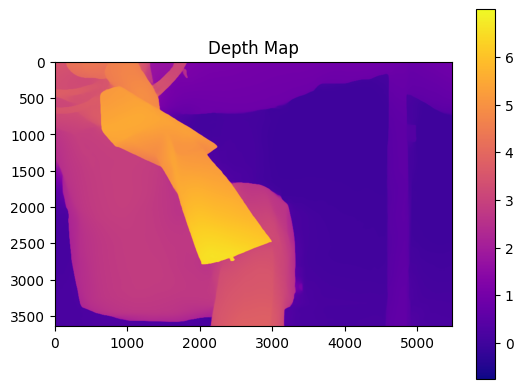

In [6]:
#View depth map in jupiter notebook

plt.imshow(disp, cmap='plasma')
plt.colorbar()
plt.title('Depth Map')
plt.show()

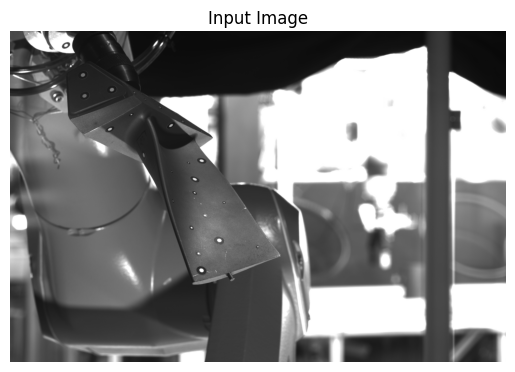

In [7]:
#Visualize image
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Input Image')
plt.axis('off')
plt.show()

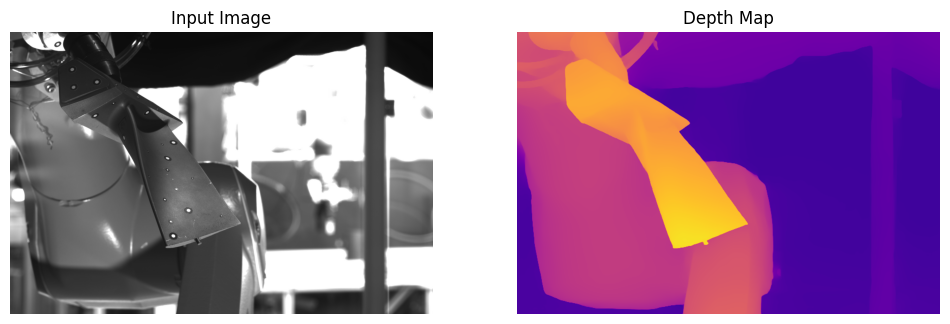

In [8]:
#Compare image and depth map image side by side
fig, axs = plt.subplots(1, 2, figsize=(12, 6))
axs[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axs[0].set_title('Input Image')
axs[0].axis('off')
axs[1].imshow(disp, cmap='plasma')
axs[1].set_title('Depth Map')
axs[1].axis('off')
plt.show()

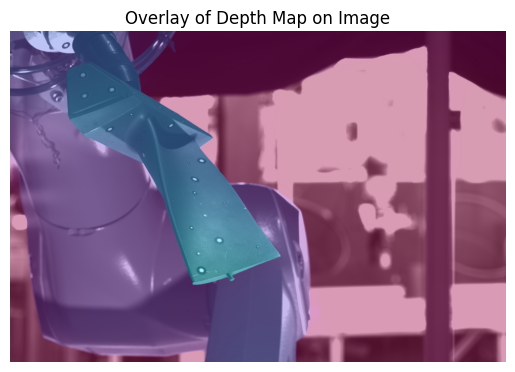

In [9]:

# Normalize the depth map to the range [0, 255]
normalized_disp = cv2.normalize(disp, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# Convert the normalized depth map to a 3-channel image
depth_colored = cv2.applyColorMap(normalized_disp, cv2.COLORMAP_PLASMA)

# Blend the input image and the depth map
overlay = cv2.addWeighted(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), 0.6, depth_colored, 0.4, 0)

# Display the overlay
plt.imshow(overlay)
plt.title('Overlay of Depth Map on Image')
plt.axis('off')
plt.show()

In [10]:
def overlay_disparity_on_image(image, disp, alpha=0.6, colormap=cv2.COLORMAP_JET):
    """
    Overlays a disparity map on top of an image.

    Args:
        image (numpy.ndarray): The base image (H, W, 3).
        disp (numpy.ndarray): The disparity map (H, W).
        alpha (float): Transparency factor for the overlay. Default is 0.6.
        colormap (int): OpenCV colormap to apply to the disparity map. Default is cv2.COLORMAP_JET.

    Returns:
        numpy.ndarray: The resulting image with the disparity overlay.
    """
    # Normalize disparity map to 0-255
    disp_normalized = cv2.normalize(disp, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    
    # Apply colormap to the normalized disparity map
    disp_colored = cv2.applyColorMap(disp_normalized, colormap)
    
    # Ensure the input image is in the correct format
    if image.dtype != np.uint8:
        image = (image * 255).astype(np.uint8)
    
    # Resize disparity map to match image size if necessary
    if disp_colored.shape[:2] != image.shape[:2]:
        disp_colored = cv2.resize(disp_colored, (image.shape[1], image.shape[0]))
    
    # Overlay the colored disparity map on the original image
    overlayed_image = cv2.addWeighted(image, 1 - alpha, disp_colored, alpha, 0)
    
    return overlayed_image


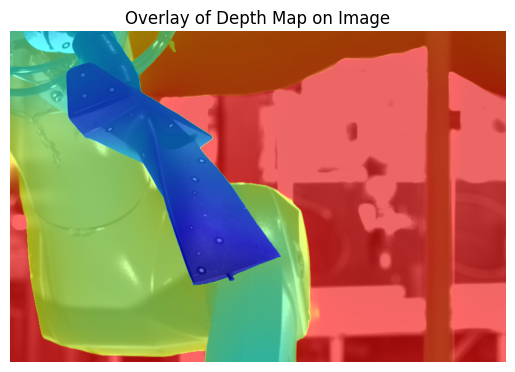

In [11]:
overlay_img = overlay_disparity_on_image(img, disp)
plt.imshow(overlay_img)
plt.title('Overlay of Depth Map on Image')
plt.axis('off')
plt.show()

In [12]:
threshold_value = 0
# Apply the threshold
disp[disp < threshold_value] = 0
    

In [13]:
calib_file ="/home/hirur/MasterThesis/3d_Reconstruction/output/batch_1/scaled_calibration_parameters.json"
calib_parameters = load_scaled_calibration_parameters(calib_file)


Successfully loaded scaled calibration parameters from: /home/hirur/MasterThesis/3d_Reconstruction/output/batch_1/scaled_calibration_parameters.json


In [14]:
print("Calibration parameters-")
print(calib_parameters["K1"]*4)

Calibration parameters-
[[2.17656248e+04 0.00000000e+00 2.72188252e+03]
 [0.00000000e+00 2.17584356e+04 1.80562909e+03]
 [0.00000000e+00 0.00000000e+00 4.00000000e+00]]


In [15]:
def get_camera_intrinsics(camera_parameters, scale_factor: int):
    K = camera_parameters * scale_factor
    fx, fy = K[0, 0], K[1, 1]
    cx, cy = K[0, 2], K[1, 2]
    return fx, fy, cx, cy

fx, fy, cx, cy = get_camera_intrinsics(calib_parameters["K1"], scale_factor=4)

In [16]:


























































height, width = depth_map.shape

# Create a grid of pixel coordinates
x, y = np.meshgrid(np.arange(width), np.arange(height))


In [17]:
def depth_to_point_cloud(depth_map, K):
    """
    Converts a depth map to a 3D point cloud using camera intrinsic parameters.

    Args:
        depth_map (numpy.ndarray): The depth map (H, W).
        K (numpy.ndarray): Camera intrinsic matrix (3x3).

    Returns:
        numpy.ndarray: The point cloud (N, 3), where N is the number of valid depth points.
    """
    # Get the intrinsic parameters
    fx, fy, cx, cy = get_camera_intrinsics(K, scale_factor=4)

    # Get the image dimensions
    height, width = depth_map.shape

    # Create a grid of pixel coordinates
    x, y = np.meshgrid(np.arange(width), np.arange(height))

    # Compute the normalized coordinates
    x_normalized = (x - cx) / fx
    y_normalized = (y - cy) / fy

    # Flatten the arrays
    x_normalized = x_normalized.flatten()
    y_normalized = y_normalized.flatten()
    depth = depth_map.flatten()

    # Filter out points with zero depth
    valid = depth > 0
    x_normalized = x_normalized[valid]
    y_normalized = y_normalized[valid]
    depth = depth[valid]

    # Compute the 3D points
    X = x_normalized * depth
    Y = y_normalized * depth
    Z = depth

    # Stack the points into a (N, 3) array
    point_cloud = np.vstack((X, Y, Z)).T

    return point_cloud



In [18]:
# Generate the point cloud
point_cloud = depth_to_point_cloud(depth_map, calib_parameters["K1"])

# Print the number of points in the point cloud
print("Number of points in the point cloud:", point_cloud.shape[0])

Number of points in the point cloud: 16951229


In [19]:
o3d_pcd= numpy_to_o3d(point_cloud)



There are 16951229 points


In [20]:
#point cloud numpy to ply file
save_point_cloud(o3d_pcd, "/home/hirur/MasterThesis/3d_Reconstruction/output/batch_1/ModelOutput/depthanything_v2")

 Point cloud saved to /home/hirur/MasterThesis/3d_Reconstruction/output/batch_1/ModelOutput/depthanything_v2/point_cloud_20251015_222926.ply 


'/home/hirur/MasterThesis/3d_Reconstruction/output/batch_1/ModelOutput/depthanything_v2/point_cloud_20251015_222926.ply'

In [21]:
def save_point_cloud_to_ply(point_cloud, filename):
    """
    Saves a point cloud to a PLY file.

    Args:
        point_cloud (numpy.ndarray): The point cloud (N, 3) or (N, 6) where N is the number of points.
                                      If (N, 6), the last three columns are treated as RGB values.
        filename (str): The output PLY file name.
    """
    with open(filename, 'w') as ply_file:
        # Write the PLY header
        ply_file.write("ply\n")
        ply_file.write("format ascii 1.0\n")
        ply_file.write(f"element vertex {point_cloud.shape[0]}\n")
        ply_file.write("property float x\n")
        ply_file.write("property float y\n")
        ply_file.write("property float z\n")
        if point_cloud.shape[1] == 6:
            ply_file.write("property uchar red\n")
            ply_file.write("property uchar green\n")
            ply_file.write("property uchar blue\n")
        ply_file.write("end_header\n")
        
        # Write the point data
        for point in point_cloud:
            ply_file.write(" ".join(map(str, point)) + "\n")

# Save the point cloud to a PLY file


In [22]:
from datetime import datetime

#add date time stamp to filename point_cloud_YYYMMDD_HHMMSS
# Generate the timestamp
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

# Create the filename with the timestamp
ply_filename = f"/home/hirur/MasterThesis/3d_Reconstruction/output/batch_1/ModelOutput/depthanything_v2/point_cloud_{timestamp}.ply"


In [23]:
# save_point_cloud_to_ply(point_cloud, ply_filename)